# 福州大学教务处通知数据分析

Foundation 2 · 数据分析作业 1

数据由爬虫作业 1（`crawler/assignment1_jwch.py`）抓取，共 700 条通知、585 个附件，
时间跨度 2023-06 至 2026-11。字段包括：通知人、标题、发布时间、详情链接、正文、
附件名 / 下载次数 / 链接。

按题目要求回答 7 个问题：

1. 数据概览与清洗
2. 通知人都有谁，各占多少
3. 「课程调整」类通知有多少、具体是什么
4. 附件下载次数与通知人的关系
5. 通知发布的高峰期
6. 自由探索：标题长度、主题与附件下载量的关系
7. 结论

> 文中所有数字都来自本次 700 条样本；换一批数据（比如爬到 2000 条）结论的**量级**会变，
> 但方向和结构应该稳定。


In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 150)

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Songti SC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110


def find_csv() -> Path:
    """在 notebook 目录和各级父目录里找爬虫产出的 CSV。"""
    cwd = Path.cwd()
    names = [
        "crawler/data/jwch_notices.csv",
        "foundation2/crawler/data/jwch_notices.csv",
        "data/jwch_notices.csv",
    ]
    for base in [cwd, *cwd.parents]:
        for name in names:
            candidate = base / name
            if candidate.exists():
                return candidate
    raise FileNotFoundError("找不到 jwch_notices.csv，先运行 crawler/assignment1_jwch.py")


CSV_PATH = find_csv()
REPORT_DIR = CSV_PATH.parent.parent.parent / "analysis" / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print("数据文件：", CSV_PATH)
print("图表目录：", REPORT_DIR)


数据文件： /Users/shaddocknh3/Desktop/github/west2-online-ai-2026-test-ai/foundation/foundation2/crawler/data/jwch_notices.csv
图表目录： /Users/shaddocknh3/Desktop/github/west2-online-ai-2026-test-ai/foundation/foundation2/analysis/report


## 1. 读入数据与概览

In [2]:
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
print(f"形状：{df.shape[0]} 行 × {df.shape[1]} 列")
df.dtypes.to_frame("类型")


形状：700 行 × 10 列


,类型
通知人,str
标题,str
发布时间,str
详情链接,str
正文,str
附件名,str
附件下载次数,str
附件链接,str
附件数量,int64
正文长度,int64


In [3]:
missing = df.isna().sum().to_frame("缺失数")
missing["缺失率"] = (missing["缺失数"] / len(df) * 100).round(2).astype(str) + "%"
missing


,缺失数,缺失率
通知人,0,0.0%
标题,0,0.0%
发布时间,0,0.0%
详情链接,0,0.0%
正文,0,0.0%
附件名,355,50.71%
附件下载次数,355,50.71%
附件链接,355,50.71%
附件数量,0,0.0%
正文长度,0,0.0%


In [4]:
df[["通知人", "标题", "发布时间", "附件数量", "正文长度"]].head(8)


,通知人,标题,发布时间,附件数量,正文长度
0,教材建设,关于做好2026-2027学年第一学期本科课程实施与教材使用监测工作的通知,2026-11-02,1,1357
1,教学运行,关于做好2027届预计毕业生电子注册图像采集工作的通知,2026-11-02,3,1492
2,实践科,关于举办2026年福州大学大学生工程实践与创新能力大赛的通知,2026-10-29,1,820
3,教学运行,关于2026-2027学年第一学期概率论与数理统计课程半期考试安排的通知,2026-10-27,1,147
4,教学运行,关于2026-2027学年第一学期高等数学A上、高等数学B上、高等数学C上、高等数学D课程半期考试安排的通知,2026-10-27,1,168
5,教学通知,福州大学教务处关于印发本科生微专业建设与管理办法的通知,2026-10-26,0,2566
6,教材建设,关于做好我校省级“十四五”普通高等教育本科规划教材建设项目验收工作的通知,2026-10-23,5,1989
7,教学运行,关于2026-2027学年第一学期高等数学A下课程半期考试安排的通知,2026-10-21,1,146


### 1.1 清洗

* `发布时间` 转 datetime，衍生「年-月」「年份」「星期」；
* `通知人` 去掉首尾空白，空白统一标成「未标注」；
* 附件下载次数是 `"86 | 90"` 这种字符串，拆回数字，再算每条通知的附件总下载量。

附件那三列有约 50% 的空缺——这不是爬漏了，而是**一半左右的通知本来就没有附件**，
后面统计时要先过滤。


In [5]:
df["发布时间"] = pd.to_datetime(df["发布时间"], errors="coerce")
df["通知人"] = df["通知人"].fillna("").astype(str).str.strip().replace("", "未标注")
df["月份"] = df["发布时间"].dt.to_period("M").astype(str)
df["年份"] = df["发布时间"].dt.year
df["星期"] = df["发布时间"].dt.day_of_week.map(
    {0: "周一", 1: "周二", 2: "周三", 3: "周四", 4: "周五", 5: "周六", 6: "周日"}
)


def parse_downloads(text: object) -> list[int]:
    """把 "86 | 90" 拆成 [86, 90]。"""
    if not isinstance(text, str) or not text.strip():
        return []
    return [int(piece) for piece in text.split("|") if piece.strip().isdigit()]


df["下载次数列表"] = df["附件下载次数"].map(parse_downloads)
df["附件总下载"] = df["下载次数列表"].map(sum)
df["有附件"] = df["附件数量"] > 0

print("时间范围：", df["发布时间"].min().date(), "→", df["发布时间"].max().date())
print("没有解析到发布时间的记录数：", df["发布时间"].isna().sum())
print("带附件的通知：", int(df["有附件"].sum()), f"（{df['有附件'].mean():.1%}）")
print("附件总数：", int(df["附件数量"].sum()))
print("标题去重后：", df["标题"].nunique(), "个（有", int(df.duplicated('标题').sum()), "条重名）")
df[["通知人", "发布时间", "月份", "星期", "附件数量", "附件总下载"]].head()


时间范围： 2023-06-29 → 2026-11-02
没有解析到发布时间的记录数： 0
带附件的通知： 345 （49.3%）
附件总数： 585
标题去重后： 675 个（有 25 条重名）


,通知人,发布时间,月份,星期,附件数量,附件总下载
0,教材建设,2026-11-02,2026-11,周一,1,15
1,教学运行,2026-11-02,2026-11,周一,3,329
2,实践科,2026-10-29,2026-10,周四,1,100
3,教学运行,2026-10-27,2026-10,周二,1,252
4,教学运行,2026-10-27,2026-10,周二,1,1533


## 2. 「通知人」都有谁？

`通知人` 是爬虫从列表页 `【】` 标签里抠出来的，实际含义就是**栏目 / 科室名**。


In [6]:
notifier_stats = (
    df["通知人"]
    .value_counts()
    .to_frame("通知数")
    .assign(占比=lambda frame: (frame["通知数"] / len(df) * 100).round(2))
)
notifier_stats["占比"] = notifier_stats["占比"].astype(str) + "%"
notifier_stats


,通知数,占比
通知人,,
教学运行,229,32.71%
实践科,149,21.29%
质量办,85,12.14%
计划科,67,9.57%
教研教改,56,8.0%
综合科,52,7.43%
教材建设,45,6.43%
教学通知,10,1.43%
电教中心,7,1.0%


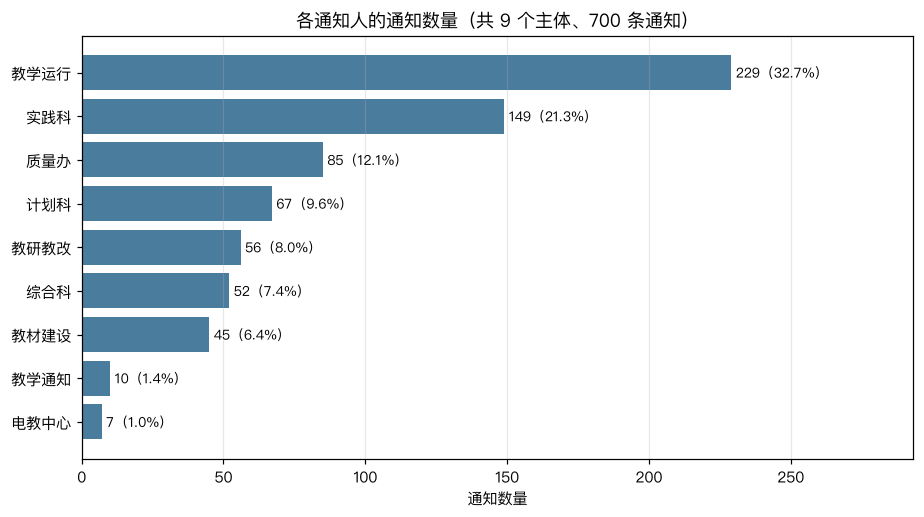

Top 3 占比合计： 66.1%


In [7]:
top = notifier_stats.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(top.index, top["通知数"], color="#4a7c9e")
ax.bar_label(bars, labels=[f"{v}（{v / len(df):.1%}）" for v in top["通知数"]], padding=3, fontsize=9)
ax.set_xlabel("通知数量")
ax.set_title(f"各通知人的通知数量（共 {df['通知人'].nunique()} 个主体、{len(df)} 条通知）")
ax.set_xlim(0, top["通知数"].max() * 1.28)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(REPORT_DIR / "01_notifier_counts.png", dpi=150)
plt.show()

print("Top 3 占比合计：", f"{notifier_stats['通知数'].head(3).sum() / len(df):.1%}")


**观察**：

* 一共 9 个发布主体，**教学运行 229 条（32.7%）** 一家独大，实践科 149 条（21.3%）、
  质量办 85 条（12.1%）跟在后面，前三个合计 66.1%——很典型的头部集中结构。
* 中间梯队（计划科 67、教研教改 56、综合科 52、教材建设 45）各占 6%–10%，
  对应「排课 / 项目申报 / 行政 / 教材」这几块相对低频的业务。
* 尾部是电教中心 7 条和「教学通知」10 条。注意 **「教学通知」不是科室名**，
  它是一部分通知直接挂到父栏目上的兜底标签；严格说应该合并回科室或单独标注，
  这里保留原样，只在下结论时留意它会让「教学运行」的占比被略微低估。


## 3. 「课程调整」类通知有多少？

按标题关键词筛：`课程调整`、`调课`、`停课`、`补课`、`课程安排`，
命中后单独导出 CSV 供人工核对。


In [8]:
KEYWORDS = ["课程调整", "调课", "停课", "补课", "课程安排"]
pattern = "|".join(KEYWORDS)
course_mask = df["标题"].astype(str).str.contains(pattern, regex=True, na=False)
course_df = df[course_mask].sort_values("发布时间", ascending=False)

print(f"命中 {len(course_df)} 条，占全部通知的 {len(course_df) / len(df):.1%}")
course_df[["发布时间", "通知人", "标题"]]


命中 18 条，占全部通知的 2.6%


,发布时间,通知人,标题
25,2026-09-14,教学运行,关于2026年中秋节和国庆节放假课程调整的通知
70,2026-06-15,教学运行,关于2026年端午节放假课程调整的通知
105,2026-04-24,教学运行,关于2026年劳动节放假课程调整的通知
127,2026-03-30,教学运行,关于2026年清明节放假课程调整的通知
179,2025-12-29,教学运行,关于2026年元旦放假课程调整的通知
216,2025-09-24,教学运行,关于2025年国庆节、中秋节放假课程调整的通知
286,2025-05-27,教学运行,关于2025年端午节放假课程调整的通知
316,2025-04-24,教学运行,关于2025年劳动节放假课程调整的通知
337,2025-04-01,教学运行,关于2025年清明节放假课程调整的通知
385,2024-12-25,教学运行,关于2025年元旦放假课程调整的通知


In [9]:
for keyword in KEYWORDS:
    hit = df["标题"].astype(str).str.contains(keyword, na=False).sum()
    print(f"{keyword:<6} {hit:>4} 条")

output_csv = CSV_PATH.parent / "course_adjust_notices.csv"
course_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
print(f"\n已导出 {len(course_df)} 条到 {output_csv}")


课程调整     18 条
调课        0 条
停课        0 条
补课        0 条
课程安排      0 条

已导出 18 条到 /Users/shaddocknh3/Desktop/github/west2-online-ai-2026-test-ai/foundation/foundation2/crawler/data/course_adjust_notices.csv


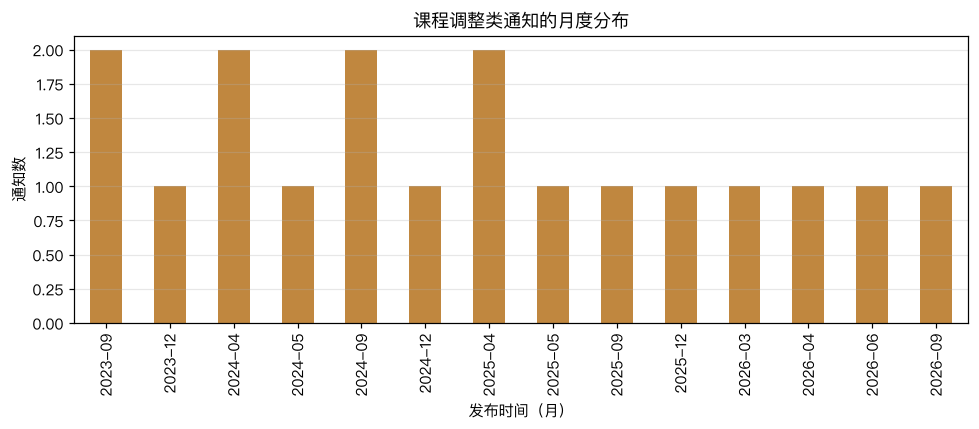

In [10]:
if course_df.empty:
    print("没有命中课程调整类通知，跳过作图。")
else:
    fig, ax = plt.subplots(figsize=(9, 4))
    counts = course_df.groupby("月份").size()
    counts.plot(kind="bar", ax=ax, color="#c0873f")
    ax.set_title("课程调整类通知的月度分布")
    ax.set_xlabel("发布时间（月）")
    ax.set_ylabel("通知数")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "02_course_adjust_by_month.png", dpi=150)
    plt.show()


**观察**：

* 命中 18 条，只占 2.6%，但**内容高度同质**：全部是「XX 节放假课程调整的通知」，
  并且全部由「教学运行」发布。
* 其余四个关键词（调课 / 停课 / 补课 / 课程安排）零命中——说明教务处命名很统一，
  这类事一律叫「课程调整」，不会散成十几种说法。
* 时间上一年 6 次左右，正好对应元旦、清明、劳动、端午、中秋、国庆六个假期，
  且都提前 1–2 周发布。这是「校历驱动」的典型数据：数量少、可预测、几乎没有异常。


## 4. 附件下载次数与通知人的关系

先把「附件」摊平成明细表（一条通知挂多个附件就拆成多行），
再按通知人聚合——一条通知挂 5 个附件不代表每个都热，所以**单个附件**才是合适的统计单位。


In [11]:
rows = []
for _, record in df.iterrows():
    names = str(record["附件名"]).split("|") if isinstance(record["附件名"], str) else []
    for name, count in zip(names, record["下载次数列表"]):
        rows.append(
            {
                "通知人": record["通知人"],
                "发布时间": record["发布时间"],
                "年份": record["年份"],
                "附件名": name.strip(),
                "下载次数": count,
            }
        )

attach = pd.DataFrame(rows)
print(f"附件明细 {len(attach)} 条，覆盖 {attach['通知人'].nunique()} 个通知人")
attach["下载次数"].describe().round(1).to_frame("下载次数统计")


附件明细 585 条，覆盖 8 个通知人


,下载次数统计
count,585.0
mean,1619.3
std,1760.5
min,15.0
25%,807.0
50%,1313.0
75%,1730.0
max,16555.0


In [12]:
by_notifier = (
    attach.groupby("通知人")["下载次数"]
    .agg(附件数="count", 平均下载="mean", 中位数="median", 最大="max")
    .sort_values("平均下载", ascending=False)
    .round(1)
)
by_notifier


,附件数,平均下载,中位数,最大
通知人,,,,
计划科,42,2459.9,2176.5,6290
教研教改,49,2159.0,1782.0,5480
实践科,140,2111.0,1464.0,16555
教学通知,10,1662.8,963.5,8522
教学运行,170,1578.8,1309.5,14875
质量办,68,1172.5,1156.0,2702
教材建设,94,745.5,750.5,1931
综合科,12,650.2,499.0,1397


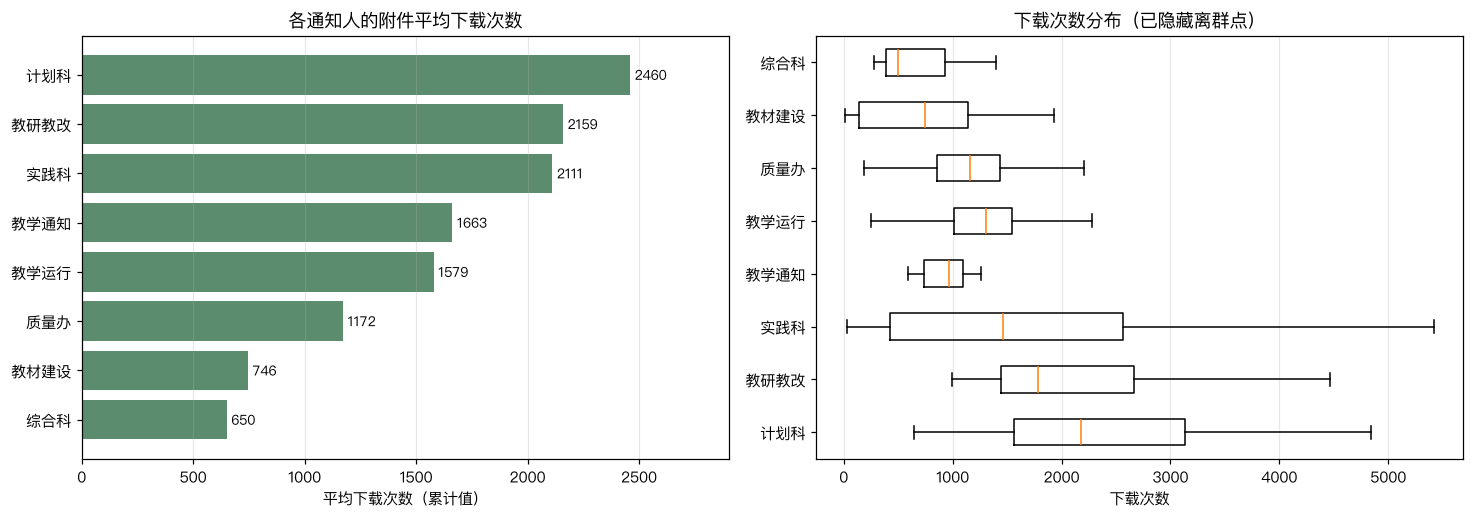

In [13]:
qualified = by_notifier.sort_values("平均下载")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

bars = axes[0].barh(qualified.index, qualified["平均下载"], color="#5b8c6e")
axes[0].bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
axes[0].set_title("各通知人的附件平均下载次数")
axes[0].set_xlabel("平均下载次数（累计值）")
axes[0].set_xlim(0, qualified["平均下载"].max() * 1.18)
axes[0].grid(axis="x", alpha=0.3)

names = list(by_notifier.index)
groups = [attach.loc[attach["通知人"] == name, "下载次数"].values for name in names]
axes[1].boxplot(groups, orientation="horizontal", tick_labels=names, showfliers=False)
axes[1].set_title("下载次数分布（已隐藏离群点）")
axes[1].set_xlabel("下载次数")
axes[1].grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(REPORT_DIR / "03_attachment_downloads.png", dpi=150)
plt.show()


### 4.1 一个必须排除的混淆因素：下载次数是累计值

校园网 CMS 的 `wbshowtimes` 是**从发布到现在的累计下载量**，
所以 2023 年的附件天然比 2026 年的多攒了两三年。如果不处理这一点，
「哪个部门附件更受欢迎」很容易变成「哪个部门爱发老通知」。


In [14]:
by_year = (
    attach.groupby("年份")["下载次数"]
    .agg(附件数="count", 平均下载="mean", 中位数="median")
    .round(0)
)
attach["天龄"] = (pd.Timestamp("2026-11-03") - attach["发布时间"]).dt.days
print("附件年龄与下载次数的相关系数：", round(attach["天龄"].corr(attach["下载次数"]), 3))
by_year


附件年龄与下载次数的相关系数： 0.345


,附件数,平均下载,中位数
年份,,,
2023,84,2505.0,1783.0
2024,199,1950.0,1447.0
2025,162,1496.0,1082.0
2026,140,759.0,705.0


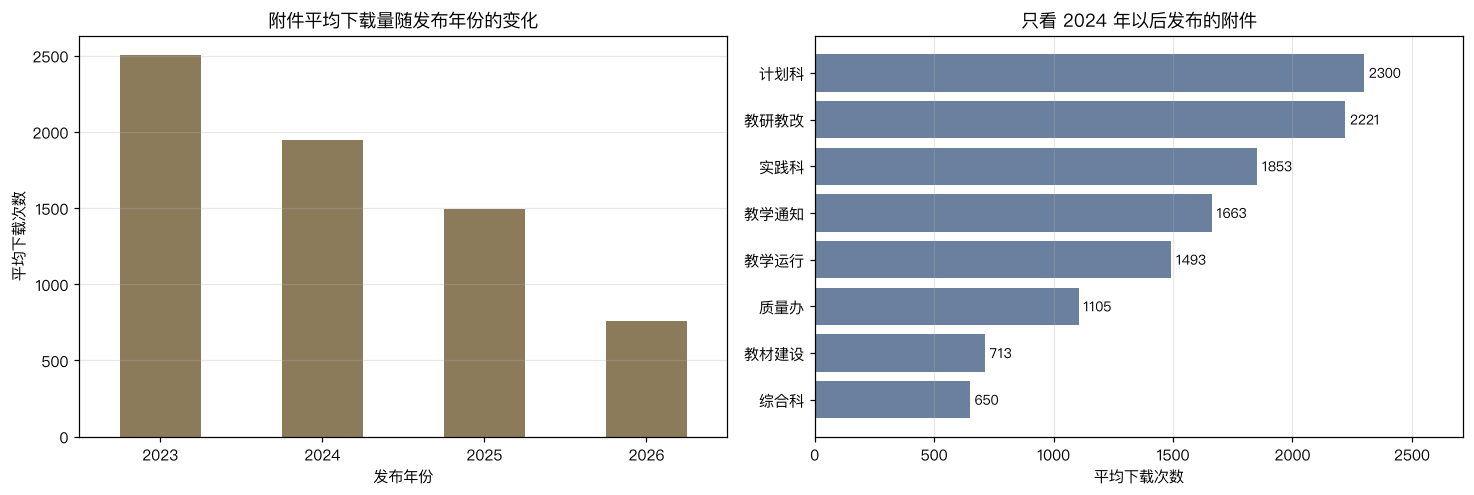

,附件数,平均下载
通知人,,
计划科,37,2300.0
教研教改,28,2221.0
实践科,116,1853.0
教学通知,10,1663.0
教学运行,146,1493.0
质量办,61,1105.0
教材建设,91,713.0
综合科,12,650.0


In [15]:
recent = attach[attach["年份"] >= 2024]
recent_stats = (
    recent.groupby("通知人")["下载次数"]
    .agg(附件数="count", 平均下载="mean")
    .round(0)
    .sort_values("平均下载", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

by_year["平均下载"].plot(kind="bar", ax=axes[0], color="#8c7b5b")
axes[0].set_title("附件平均下载量随发布年份的变化")
axes[0].set_xlabel("发布年份")
axes[0].set_ylabel("平均下载次数")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

bars = axes[1].barh(recent_stats.index[::-1], recent_stats["平均下载"][::-1], color="#6b7f9e")
axes[1].bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
axes[1].set_title("只看 2024 年以后发布的附件")
axes[1].set_xlabel("平均下载次数")
axes[1].set_xlim(0, recent_stats["平均下载"].max() * 1.18)
axes[1].grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(REPORT_DIR / "04_downloads_by_year.png", dpi=150)
plt.show()
recent_stats


**结论**：

1. **累计效应确实存在**：2023 年发布的附件平均 2505 次下载，2024 年 1950、
   2025 年 1496、2026 年只有 759；附件年龄与下载次数的相关系数是 0.345（中等偏弱正相关）。
   所以直接拿绝对数比部门并不公平。
2. 但**把样本限制到 2024 年以后，排名几乎没变**：计划科 2300、教研教改 2221、
   实践科 1853、教学通知 1663、教学运行 1493、质量办 1105、教材建设 713、综合科 650。
   说明部门之间的差异是真实的，不是「谁发的老通知多」造成的假象。
3. 差异的根源是**附件类型**：
   * 计划科 / 教研教改 / 实践科发的是「办事型」附件——申报书模板、审批表、
     实习安排表，不下载就办不了事；
   * 教学运行的附件总量最大，但多是考场安排、名单，属于「看一眼就行」，
     单件平均反而排在中游；
   * 教材建设、综合科的附件多是制度文件的附件版，正文里已经说清楚了。
4. 所以「附件下载次数与通知人的关系」，更准确的说法是
   **「附件下载次数与附件功能（要不要动手填）的关系」，部门只是这个功能的代理变量**。


## 5. 通知发布的高峰期

先看月度总量，再看「一周里的哪一天」。


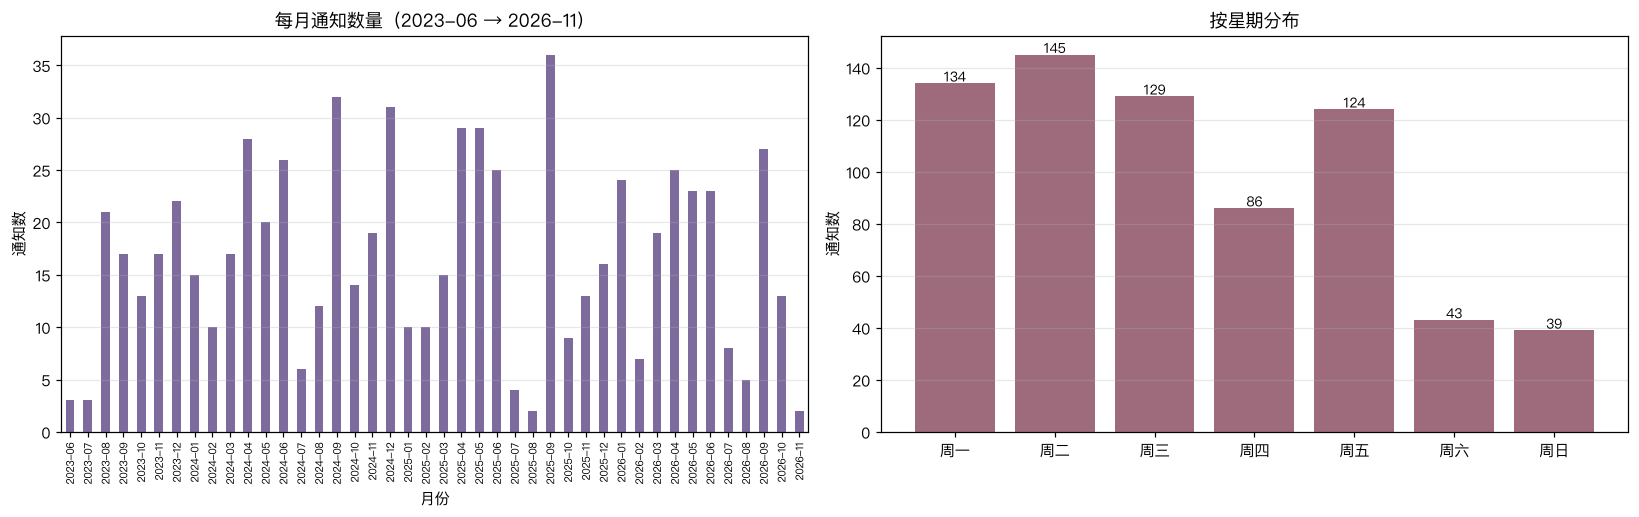

发布最多的 5 个月：
月份
2025-09    36
2024-09    32
2024-12    31
2025-05    29
2025-04    29

按月（1-12 月）汇总：
发布时间
1      49
2      27
3      51
4      82
5      72
6      77
7      21
8      40
9     112
10     49
11     51
12     69

周末发布占比： 11.71%


In [16]:
monthly = df.groupby("月份").size()
weekly = df["星期"].value_counts().reindex(["周一", "周二", "周三", "周四", "周五", "周六", "周日"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

if monthly.empty:
    print("没有可用月份数据，跳过作图。")
else:
    monthly.plot(kind="bar", ax=axes[0], color="#7d6b9e")
    axes[0].set_title(f"每月通知数量（{monthly.index[0]} → {monthly.index[-1]}）")
    axes[0].set_xlabel("月份")
    axes[0].set_ylabel("通知数")
    axes[0].tick_params(axis="x", rotation=90, labelsize=7)
    axes[0].grid(axis="y", alpha=0.3)

    bars = axes[1].bar(weekly.index, weekly.values, color="#9e6b7d")
    axes[1].bar_label(bars, fontsize=9)
    axes[1].set_title("按星期分布")
    axes[1].set_ylabel("通知数")
    axes[1].grid(axis="y", alpha=0.3)

    fig.tight_layout()
    fig.savefig(REPORT_DIR / "05_publish_time.png", dpi=150)
    plt.show()

    print("发布最多的 5 个月：")
    print(monthly.sort_values(ascending=False).head(5).to_string())
    print("\n按月（1-12 月）汇总：")
    print(df.groupby(df["发布时间"].dt.month).size().to_string())
    print("\n周末发布占比：", f"{df['星期'].isin(['周六', '周日']).mean():.2%}")


**观察**：

* 月度上两个峰：**9 月最多（112 条）**，其次是 4 月（82）、6 月（77）、5 月（72）、12 月（69）。
  9 月是开学季（选课、学籍、补考、转专业全挤在一起），4–6 月是期中、毕业季和期末，
  12 月是四六级 + 期末 + 下学期排课。
* 低谷是 1–2 月和 7–8 月，也就是寒暑假——这两个月加起来还不如 9 月一个月。
* 按星期看，周二 145、周一 134、周三 129、周五 124、周四 86 是主力；
  但**周末并不是零**：周六 43 + 周日 39，占 11.7%。
  这多半是定时发布或紧急通知（比如假期里的调课安排）。


## 6. 自由探索

两个问题：

1. **标题越长，附件下载越多吗？**
2. **不同主题的通知，附件受关注程度一样吗？**


样本 345 条
标题长度 vs 附件总下载：r = -0.239
正文长度 vs 附件总下载：r = 0.155


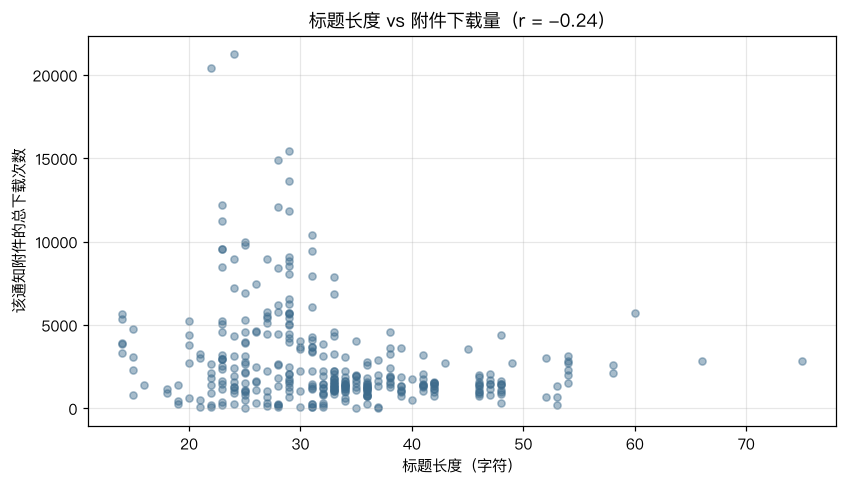

In [17]:
with_attach = df[df["有附件"] & df["附件总下载"].notna()].copy()
with_attach["标题长度"] = with_attach["标题"].astype(str).str.len()

corr_title = with_attach["标题长度"].corr(with_attach["附件总下载"])
corr_body = with_attach["正文长度"].corr(with_attach["附件总下载"])
print(f"样本 {len(with_attach)} 条")
print(f"标题长度 vs 附件总下载：r = {corr_title:.3f}")
print(f"正文长度 vs 附件总下载：r = {corr_body:.3f}")

fig, ax = plt.subplots(figsize=(7.8, 4.5))
ax.scatter(with_attach["标题长度"], with_attach["附件总下载"], alpha=0.45, s=22, color="#3d6b8c")
ax.set_xlabel("标题长度（字符）")
ax.set_ylabel("该通知附件的总下载次数")
ax.set_title(f"标题长度 vs 附件下载量（r = {corr_title:.2f}）")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(REPORT_DIR / "06_title_length_vs_download.png", dpi=150)
plt.show()


In [18]:
TOPICS = {
    "考试": ["考试", "补考", "重修", "四六级"],
    "选课": ["选课", "课程", "排课"],
    "教材": ["教材", "征订"],
    "学籍": ["学籍", "毕业", "学位", "转专业"],
    "竞赛": ["竞赛", "大赛", "申报", "评选"],
    "放假": ["放假", "调休", "节假日"],
}

records = []
for topic, words in TOPICS.items():
    mask = with_attach["标题"].astype(str).str.contains("|".join(words), regex=True, na=False)
    subset = with_attach[mask]
    records.append(
        {
            "主题": topic,
            "通知数": len(subset),
            "平均附件总下载": round(subset["附件总下载"].mean(), 1) if len(subset) else np.nan,
            "中位下载": subset["附件总下载"].median() if len(subset) else np.nan,
        }
    )

topic_df = pd.DataFrame(records).sort_values("平均附件总下载", ascending=False)
topic_df


,主题,通知数,平均附件总下载,中位下载
3,学籍,35,4919.5,4281.0
4,竞赛,57,2559.5,1949.0
2,教材,30,2400.8,1966.0
1,选课,159,1969.1,1407.0
0,考试,118,1391.7,1332.0
5,放假,0,NaN,NaN


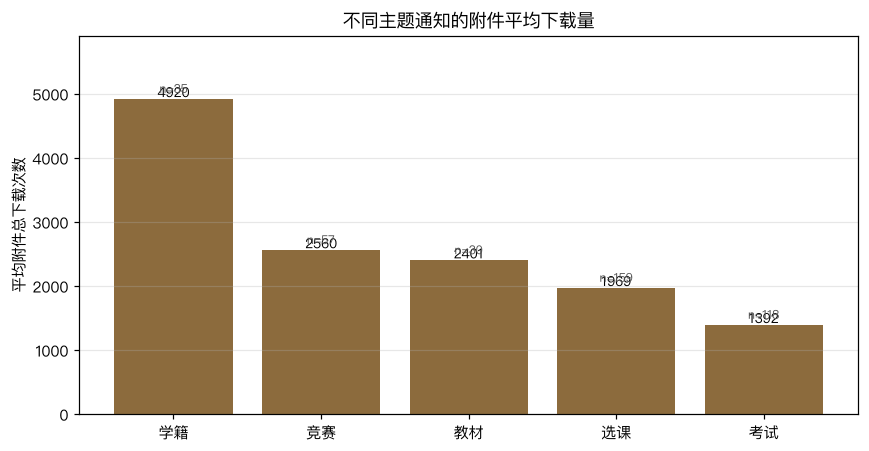

In [19]:
plot_df = topic_df.dropna(subset=["平均附件总下载"])
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(plot_df["主题"], plot_df["平均附件总下载"], color="#8c6b3d")
ax.bar_label(bars, fmt="%.0f", fontsize=9)
for index, row in plot_df.reset_index(drop=True).iterrows():
    ax.annotate(
        f"n={int(row['通知数'])}",
        xy=(index, row["平均附件总下载"]),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="#555555",
    )
ax.set_ylabel("平均附件总下载次数")
ax.set_title("不同主题通知的附件平均下载量")
ax.set_ylim(0, plot_df["平均附件总下载"].max() * 1.2)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(REPORT_DIR / "07_topic_vs_download.png", dpi=150)
plt.show()


**发现**：

1. 标题长度与附件下载量是**弱负相关**（r ≈ -0.24）：标题越短，附件反而下得多一点。
   合理的解释是「短标题 + 附件」往往意味着正文很简短、重点全在附件里
   （比如「关于做好 XX 工作的通知」配一张表），而长标题通常正文就写清了、
   附件只是补充。不过 r 只有 0.24，只能算弱信号。
2. 同样地，**正文长度与附件下载是弱正相关**（r ≈ 0.16）。两条结论方向相反，
   说明「标题长度」和「正文长度」捕捉的是不同的东西，
   不能用「篇幅越长越受关注」一句话概括。
3. 按主题看，**学籍类附件下载最高（平均约 4919）**，其次是竞赛（2560）、教材（2401）、
   选课（1969）、考试（1392）；「放假」类一条附件都没有——放假通知正文就说完了。
4. 这和 §4 的结论互相印证：附件下载量反映的是**办事需求**，不是通知的重要性，
   更不是部门的权重。


## 7. 结论

1. **发布主体高度集中**：9 个主体里「教学运行」占 32.7%，前三个合计 66.1%，
   是典型的头部集中结构。另有 10 条通知挂在「教学通知」这个非科室的兜底标签下，
   做部门统计时要留意这层噪音。

2. **「课程调整」类通知共 18 条（2.6%）**，全部是节假日放假调课、全部由教学运行发布，
   一年 6 次左右、提前 1–2 周发布，几乎没有异常。
   已单独导出到 `crawler/data/course_adjust_notices.csv`。

3. **附件下载次数与通知人确实相关，但真正的解释变量是「附件要不要动手填」**：
   计划科、教研教改、实践科的平均下载（2300 / 2221 / 1853）明显高于
   教材建设、综合科（713 / 650）。控制住「累计时间」这个混淆因素后排序基本不变，
   说明差异是真实的。

4. **发布节奏和校历强绑定**：9 月是绝对高峰（112 条），4–6 月与 12 月次之，
   寒暑假是低谷；工作日为主，周末仍占 11.7%（定时发布或紧急通知）。

5. **标题长度与下载量弱负相关（-0.24）、正文长度弱正相关（0.16）**，
   两者方向相反，说明篇幅不是好指标；主题（学籍 / 竞赛）才是更强的信号。

### 可以继续做的

* 把「教学通知」这类兜底栏目映射回科室，再重算占比；
* 按学年（9 月–次年 8 月）而不是自然年切分，峰值会更干净；
* 对正文做中文分词 + 关键词共现，看「转专业」「推免」这类词是否在特定学期爆发；
* 如果能拿到附件下载的时间序列（而不是累计值），就能画真正的「热度衰减曲线」。
